In [1]:
import torch 
from torch import nn, Tensor
import numpy as np

import matplotlib.pyplot as plt

In [2]:
class Flow(nn.Module):
    def __init__(self, dim: int = 1, h: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim + 1, h), # (t, x_t)
            nn.ELU(),
            nn.Linear(h, h),
            nn.ELU(),
            nn.Linear(h, h), 
            nn.ELU(),
            nn.Linear(h, dim)
        )
    
    def forward(self, t: Tensor, x_t: Tensor) -> Tensor:
        return self.net(torch.cat((t, x_t), -1)) # v_x
    
    def step(self, x_t: Tensor, t_start: Tensor, t_end: Tensor) -> Tensor:
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        delta = t_end - t_start
        # rk2 solver
        return x_t + delta * self(t=t_start + delta / 2, x_t= x_t + self(x_t=x_t, t=t_start) * delta / 2)

# Training

In [3]:
flow = Flow().cuda()
N = 10000
optimizer = torch.optim.Adam(flow.parameters(), 1e-2)
loss_fn = nn.MSELoss()

for _ in range(10000):
    x_0 = torch.rand(N, 1).cuda()
    x_1 = torch.randn(N, 1).cuda()
    t = torch.rand(N, 1).cuda()
    
    x_t = (1 - t) * x_0 + t * x_1
    dx_t = x_1 - x_0
    
    optimizer.zero_grad()
    loss_fn(flow(t=t, x_t=x_t), dx_t).backward()
    optimizer.step()

# Sampling

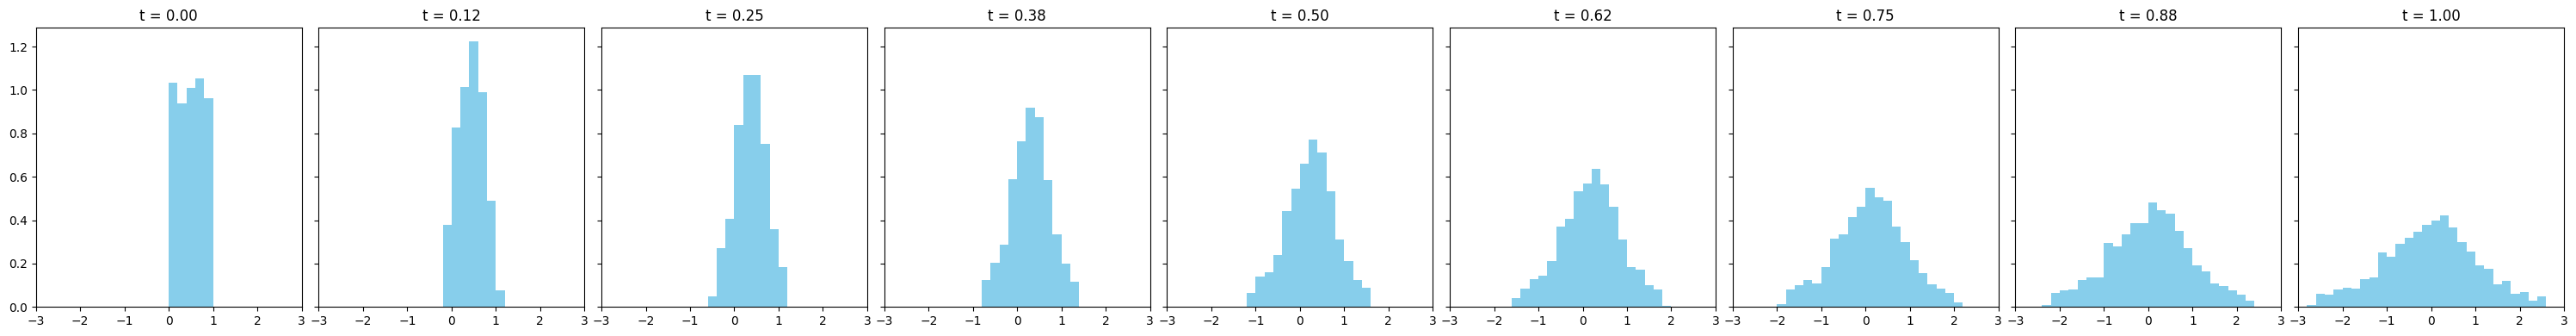

In [4]:
flow = flow.cpu()
N = 1000
x = torch.rand(N, 1)  # (300, 1)
n_steps = 8
time_steps = torch.linspace(0, 1.0, n_steps + 1)

fig, axes = plt.subplots(1, n_steps + 1, figsize=(30, 4), sharey=True)

# t=0 的分布
axes[0].hist(x.detach().squeeze().numpy(), bins=30, range=(-3, 3), color='skyblue', density=True)
axes[0].set_title(f't = {time_steps[0]:.2f}')
axes[0].set_xlim(-3.0, 3.0)

# 后续每一步的分布
for i in range(n_steps):
    x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    axes[i + 1].hist(x.detach().squeeze().numpy(), bins=30, range=(-3, 3), color='skyblue', density=True)
    axes[i + 1].set_title(f't = {time_steps[i + 1]:.2f}')
    axes[i + 1].set_xlim(-3.0, 3.0)

plt.tight_layout()
plt.show()

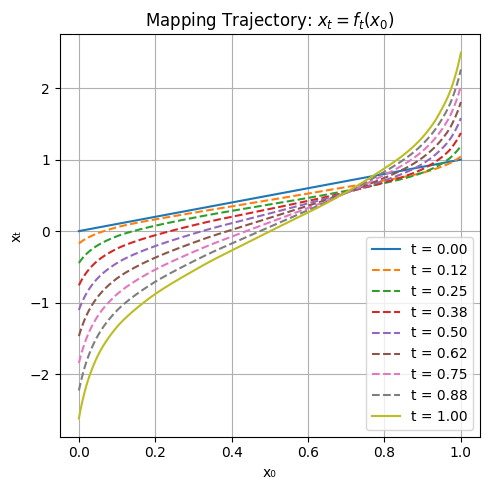

In [5]:

# 初始化输入：均匀采样的一维输入点
x0 = torch.linspace(0, 1, 3000).unsqueeze(1)  # shape (300, 1)
n_steps = 8
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# 存储每个时间步的 x_t
xt_list = [x0.detach().clone()]

x = x0.clone()
for i in range(n_steps):
    x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    xt_list.append(x.detach().clone())

# 可视化：每条线表示一个 t 的映射函数
plt.figure(figsize=(5, 5))
for i, xt in enumerate(xt_list):
    t = time_steps[i]
    if i == 0 or i == n_steps:
        plt.plot(x0.squeeze(), xt.squeeze(), label=f"t = {t:.2f}")
    else:
        plt.plot(x0.squeeze(), xt.squeeze(), '--', label=f"t = {t:.2f}")

# # 恒等线 y = x₀
# plt.plot(x0.squeeze(), x0.squeeze(), '--', color='gray', label='y = x')

plt.xlabel("x₀")
plt.ylabel("xₜ")
plt.title("Mapping Trajectory: $x_t = f_t(x_0)$")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Compare to the Inverse CDF of normal distribution. (There's no closed form expression for the inverse cdf of a normal)

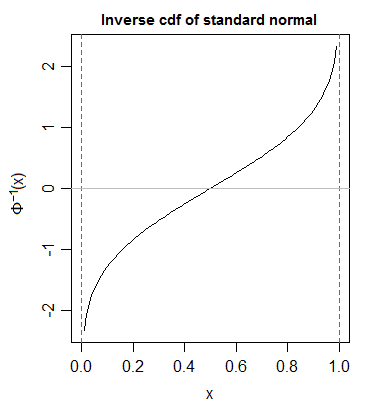

/tmp/ipykernel_2141349/1616881782.py:110: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


<Figure size 1200x400 with 0 Axes>

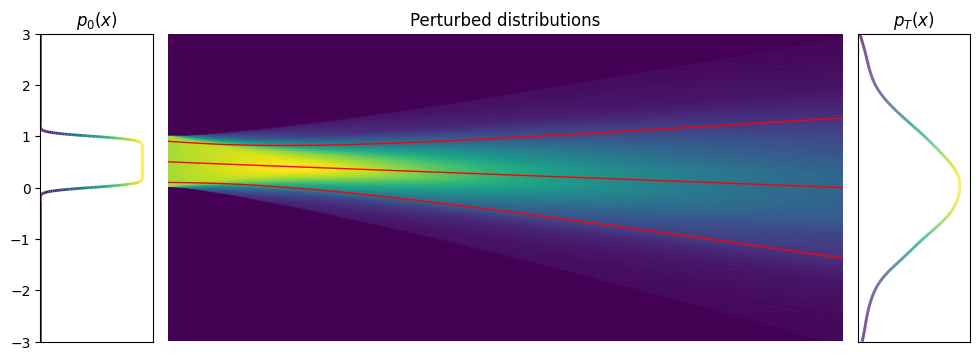

In [6]:
from matplotlib.collections import LineCollection
from scipy.stats import gaussian_kde

# 初始化输入：均匀采样的一维输入点
x0 = torch.linspace(0, 1, 3000).unsqueeze(1)  # shape (300, 1)
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# 存储每个时间步的 x_t
xt_list = [x0.detach().clone()]

x = x0.clone()
for i in range(n_steps):
    x = flow.step(x_t=x, t_start=time_steps[i], t_end=time_steps[i + 1])
    xt_list.append(x.detach().clone())

# 创建 heatmap 数据（纵轴为 x，横轴为 t）
x_range = (-3, 3)
n_bins_x = 300
heatmap = np.zeros((n_bins_x, len(time_steps)))
x_grid = np.linspace(*x_range, n_bins_x)

for i, xt in enumerate(xt_list):
    hist, _ = np.histogram(xt.numpy(), bins=n_bins_x, range=x_range, density=True)
    heatmap[:, i] = hist

track_points = torch.tensor([0.1, 0.5, 0.9]).unsqueeze(1)  # shape (3, 1)

# 找到 track_points 在 x0 中的最近索引
# 这里因为 x0 是均匀 linspace 0~1，长度3000，直接算索引：
# index = int(point * (N-1))
N = x0.shape[0]
indices = (track_points.squeeze() * (N - 1)).long()

# 准备存储轨迹数据：每个点随时间的值
tracked_trajectories = []

for idx in indices:
    traj = []
    for xt in xt_list:
        traj.append(xt[idx].item())  # 取第 idx 个点对应的值
    tracked_trajectories.append(traj)

# --- 绘图 ---

fig = plt.figure(figsize=(12, 4))
gs = plt.GridSpec(1, 3, width_ratios=[1, 6, 1], wspace=0.05)

# 工具函数：根据 kde 值渐变上色绘图
def plot_kde_colored(ax, samples, x_range, cmap='viridis', linewidth=2):
    kde = gaussian_kde(samples)
    x = np.linspace(*x_range, 1000)
    y = kde(x)

    # 构建带颜色的 LineCollection
    points = np.array([y, x]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    norm = plt.Normalize(y.min(), y.max())
    lc = LineCollection(segments, cmap=cmap, norm=norm)
    lc.set_array(y)
    lc.set_linewidth(linewidth)
    ax.add_collection(lc)

    ax.set_xlim(0, y.max() * 1.1)
    ax.set_ylim(*x_range)

# 开始绘图
fig = plt.figure(figsize=(12, 4))
gs = plt.GridSpec(1, 3, width_ratios=[1, 6, 1], wspace=0.05)

# 左边 p_0(x)：渐变色 KDE（纵轴为 x）
ax0 = fig.add_subplot(gs[0])
plot_kde_colored(ax0, xt_list[0].squeeze().numpy(), x_range)
ax0.set_xticks([])
# ax0.set_yticks([])
# ax0.invert_xaxis()
ax0.set_title(r"$p_0(x)$")

# 中间 heatmap
ax1 = fig.add_subplot(gs[1])
extent = [0, 1.0, *x_range]
ax1.imshow(
    heatmap,
    extent=extent,
    origin='lower',
    aspect='auto',
    cmap='viridis'
)
ax1.set_xlabel(r"$t$")
ax1.set_ylabel(r"$x$")
ax1.axis('off')
ax1.set_title("Perturbed distributions")


# 画轨迹：每条轨迹是t的变化（横轴） vs 该点的值（纵轴）
time_array = time_steps.numpy()

colors = ['r', 'r', 'r']
for traj, c, pt in zip(tracked_trajectories, colors, track_points.squeeze().numpy()):
    ax1.plot(time_array, traj, color=c, lw=1, label=f"x0={pt:.1f}")
# ax1.legend(loc='upper right')

# 右边 p_T(x)：渐变色 KDE（纵轴为 x）
ax2 = fig.add_subplot(gs[2])
plot_kde_colored(ax2, xt_list[-1].squeeze().numpy(), x_range)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_title(r"$p_T(x)$")

plt.tight_layout()
plt.show()
